# Trabalho Final - Tópicos Avançados em Inteligência Artificial

## Aprendizado de Máquina Explicável - Energia de Nanopartículas para Catálise

## Introdução:

As mudanças climáticas são um dos maiores problemas da humanidade atualmente, sendo causadas pelo acúmulo de gases do efeito estufa (GEE's) oriundos de emissão de veículos, indústrias e outros produtos antropogênicos. Dentre os poluentes atmosféricos gerados estão o monóxido de nitrogênio (NO) e o gás carbônico ($CO_2$), os quais são formados a partir de processos de combustão, como em usinas de energia, fábricas de produtos químicos e transporte, além de serem um dos principais responsáveis por problemas ambientais e de saúde. [1,2]

Sendo assim, a reação de redução de NO (NORR) apresenta-se como uma alternativa promissora à remoção desse gás na atmosfera, convertendo-o em amônia ($NH_3$), um composto muito importante presente na produção de fertilizantes e na indústria química. [3] Embora a NORR seja uma alternativa relevante, minimizando os gases poluentes e sintetizando $NH_3$ através da redução eletroquímica de NO, seu desenvolvimento está restrito à ausência de bons catalisadores que reduzam a barreira energética necessária para ocorrer a reação. [4] Nesse sentido, as nanopartículas (NP’s) estão sendo amplamente estudadas, apresentando-se como materiais promissores para a atividade catalítica da NORR devido a sua alta razão área/massa, o que aumenta o número de sítios ativos para a reação. [5,6,7]

No meu projeto de Iniciação Científica, estudei a atividade catalítica de NPs de Cobre e Rutênio, realizando simulações computacionais [8]. Agora neste trabalho, o objetivo é aplicar modelos de Aprendizado de Máquina para entender quais atributos influenciam na energia total da nanopartícula, utilizando ferramentas de explicabilidade para descrever o sistema.

* Inteligência Artificial foi usada nesse trabalho, principalmente para a obtenção dos dados através do script, além auxiliar em erros de código.

## Importações e Definições:

Importando as bibliotecas necessárias, talvez seja necessário instalar as bibliotecas comentadas a seguir no seu ambiente:

In [79]:
#%pip install pymatgen
#%pip install formulaic
#%pip install pygam

In [80]:
import os
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
import seaborn as sns
import plotly.express as px

from ase.io import read
from pymatgen.io.vasp import Outcar, Vasprun
import statsmodels.api as sm
from formulaic import Formula
from pygam import GAM, LinearGAM, GammaGAM, f, l, s, te

from sklearn.preprocessing import StandardScaler, OneHotEncoder, MaxAbsScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import f1_score, root_mean_squared_error

Definindo os hiperparâmetros do modelo, como a semente aleatória para reprodutibilidade; tamanho dos dados de teste; limite de confiança para plotar os gráficos de dependência parcial dos modelos; e quais são os atributos e o *target* a ser previsto. Caso não saiba quais atributos você quer treinar, uma estratégia é realizar a seleção de atributos, que pode ser feita por diferentes métodos, como o Fator de Inflação de Variância (VIF). [9]

In [81]:
# Hiperparâmetros
RANDOM_SEED = 2026
TEST_SIZE = 0.1
CONFIANCA = 0.95

# No caso já tenho uma ideia de quais atributos quero testar
continuous_cols = [ 
    "d_band_center_Ru_eV", 
    "total_mag_muB", 
    "binding_distance_A"
]
categorical_cols = ["adsorption_site"] # necessário para tratar os dados depois

FEATURES = continuous_cols + categorical_cols 
TARGET = ["total_energy_eV"] 

Criando funções base para a plotagem de gráficos, adaptado peloo Material de Aula da disciplina. [10]

In [82]:
def plota_grafico(y_real, y_predito):
    """Gera gráfico de y predito por y real."""

    figura, eixo = plt.subplots(figsize=(4, 4))
    
    # Garante que ambos são arrays 1D estritos
    y_r = np.asarray(y_real).ravel()
    y_p = np.asarray(y_predito).ravel()

    # Extrai escalares numéricos estritos
    min_y = float(min(np.min(y_r), np.min(y_p)))
    max_y = float(max(np.max(y_r), np.max(y_p)))

    eixo.plot([min_y, max_y], [min_y, max_y], c="red", ls=":")
    eixo.scatter(y_real, y_predito, alpha=0.2, linewidths=0)

    eixo.set(xlabel="$y$ verdadeiro", ylabel="$y$ predito")

    plt.show()

    RMSE = root_mean_squared_error(y_real, y_predito)
    print(f"O RMSE do modelo foi de {RMSE:.2f}.")

def plota_dep_parcial(modelo, confianca):
    """Gera gráficos de dependência parcial de modelos do PyGAM."""

    for i, termo in enumerate(modelo.terms):
        if not termo.isintercept:

            XX = modelo.generate_X_grid(term=i)
            par_dep, conf = modelo.partial_dependence(
                term=i,
                X=XX,
                width=confianca,
            )

            figura, eixo = plt.subplots()

            eixo.plot(XX[:, termo.feature], par_dep)
            eixo.plot(XX[:, termo.feature], conf, c="r", ls="--")
            eixo.set(
                title=repr(termo),
                ylabel="Impacto no target",
                xlabel="Valor do atributo",
            )

            plt.show()


Carregando os dados das Nanopartículas, cujo script associado está no arquivo <code>Script - Dados NP.py</code> e os datasets estão na pasta *Datasets*:

In [83]:
df_Ndown = pd.read_csv('../dataset_N-down.csv')
df_Odown = pd.read_csv('../dataset_O-down.csv')

df = pd.concat([df_Ndown, df_Odown], ignore_index=True)

df.dropna(inplace=True)

print(f'Existem {len(df.columns)} colunas:', df.columns)

df.head()

Existem 45 colunas: Index(['pathway', 'intermediate', 'stage', 'conformation', 'folder_path',
       'total_energy_eV', 'energy_per_atom_eV', 'energy_per_metal_eV',
       'e_fermi_eV', 'converged_electronic', 'converged_ionic',
       'n_ionic_steps', 'max_force_eV_A', 'n_total_atoms', 'n_metal_atoms',
       'r_gyration_metal_A', 'np_com_x', 'np_com_y', 'np_com_z',
       'np_surf_min_r', 'np_surf_mean_r', 'np_surf_max_r', 'adsorbate_formula',
       'n_adsorbate_atoms', 'binding_adsorbate_atom', 'closest_metal_element',
       'closest_metal_index', 'binding_distance_A', 'coordination_number_2_4A',
       'adsorption_site', 'ads_com_x', 'ads_com_y', 'ads_com_z',
       'ads_internal_bonds', 'ads_coordinates', 'total_mag_muB', 'abs_mag_muB',
       'core_Cu_mag_mean', 'surf_Ru_mag_mean', 'binding_metal_mag',
       'adsorbate_total_mag', 'd_band_center_Ru_eV', 'd_band_width_Ru_eV',
       'd_band_center_Cu_eV', 'd_band_width_Cu_eV'],
      dtype='object')


,pathway,intermediate,stage,conformation,folder_path,total_energy_eV,energy_per_atom_eV,energy_per_metal_eV,e_fermi_eV,converged_electronic,...,total_mag_muB,abs_mag_muB,core_Cu_mag_mean,surf_Ru_mag_mean,binding_metal_mag,adsorbate_total_mag,d_band_center_Ru_eV,d_band_width_Ru_eV,d_band_center_Cu_eV,d_band_width_Cu_eV
0,N-down,HNO,screening_final,conf_0,/home/enzo24035/IC/Intermediarios/N-down/HNO/d...,-368.603075,-6.355225,-6.701874,-3.073579,True,...,37.021767,32.844,0.112154,0.745143,0.100,-0.024,-2.395196,1.549157,-3.145170,1.290361
1,N-down,HNO,screening_final,conf_1,/home/enzo24035/IC/Intermediarios/N-down/HNO/d...,-369.739099,-6.374812,-6.722529,-3.065844,True,...,33.205613,29.403,0.112154,0.663119,0.109,-0.034,-2.421278,1.565696,-3.111374,1.286968
3,N-down,HNO,screening_final,conf_3,/home/enzo24035/IC/Intermediarios/N-down/HNO/d...,-369.452808,-6.369876,-6.717324,-3.042190,True,...,35.069471,31.042,0.109231,0.703095,0.138,-0.032,-2.405695,1.576375,-3.119109,1.287686
4,N-down,HNO,screening_final,conf_4,/home/enzo24035/IC/Intermediarios/N-down/HNO/d...,-368.436705,-6.352357,-6.698849,-3.063164,True,...,33.166544,31.548,0.098846,0.672262,0.039,-0.014,-2.438058,1.564627,-3.118693,1.290259
5,N-down,N,screening,conf_0,/home/enzo24035/IC/Intermediarios/N-down/N/doc...,-359.134000,-6.413107,-6.529709,-3.054004,True,...,42.067192,37.504,0.110077,0.853000,-0.061,-0.041,-2.401110,1.601956,-3.169277,1.285279


A descrição de cada componente está detalhada no arquivo <code>READ ME</code>, mas a tabela a seguir resume os dados de interesse:

| Coluna|Papel|Tipo|Descrição|Unidade|
|---|---|---|---|---|
| <code>d_band_center_Ru_eV</code>|Atributo|Contínuo|Centro da banda d para o Rutênio|eV|
| <code>total_mag_muB</code>|Atributo|Contínuo|Magnetização total da molécula adsorvida na NP|$\mu_B$|
| <code>binding_distance_A</code>|Atributo|Contínuo|Distância de ligação entre o adsorbato e a NP|$\AA$|
| <code>adsorption_site</code>|Atributo|Nominal|Sítio de adsorção da NP (*Atop*, *Bridge* e *Hollow*)||
| <code>total_energy_eV</code>|Alvo|Contínuo|Energia extraída por átomo|eV|


## Tratamento dos dados:

Analisando a distribuição e característica dos dados:

In [84]:
df[["e_fermi_eV", "d_band_center_Ru_eV", "total_mag_muB", 
    "binding_distance_A", "adsorption_site", "total_energy_eV"]].describe(include = 'all')

,e_fermi_eV,d_band_center_Ru_eV,total_mag_muB,binding_distance_A,adsorption_site,total_energy_eV
count,55.000000,55.000000,55.000000,55.000000,55,55.000000
unique,NaN,NaN,NaN,NaN,3,NaN
top,NaN,NaN,NaN,NaN,top,NaN
freq,NaN,NaN,NaN,NaN,26,NaN
mean,-3.039446,-2.411091,36.964621,1.946676,NaN,-365.889237
std,0.061984,0.020916,4.055988,0.163690,NaN,4.250782
min,-3.152505,-2.476808,29.677618,1.637047,NaN,-375.147658
25%,-3.075738,-2.421389,34.680959,1.857820,NaN,-368.925786
50%,-3.045910,-2.405695,35.308506,1.971488,NaN,-365.973708
75%,-3.014333,-2.396469,37.627286,2.090632,NaN,-362.905389


Perceba que todos possuem 55 valores, sendo o número total de átomos da NP. Note que não há uma variação tão grande na escala para os atributos, representado pelo baixo desvio padrão; no entanto, será feito um tratamento dos dados para o treinamento dos modelos.

Visualizando melhor a distribuição dos dados:

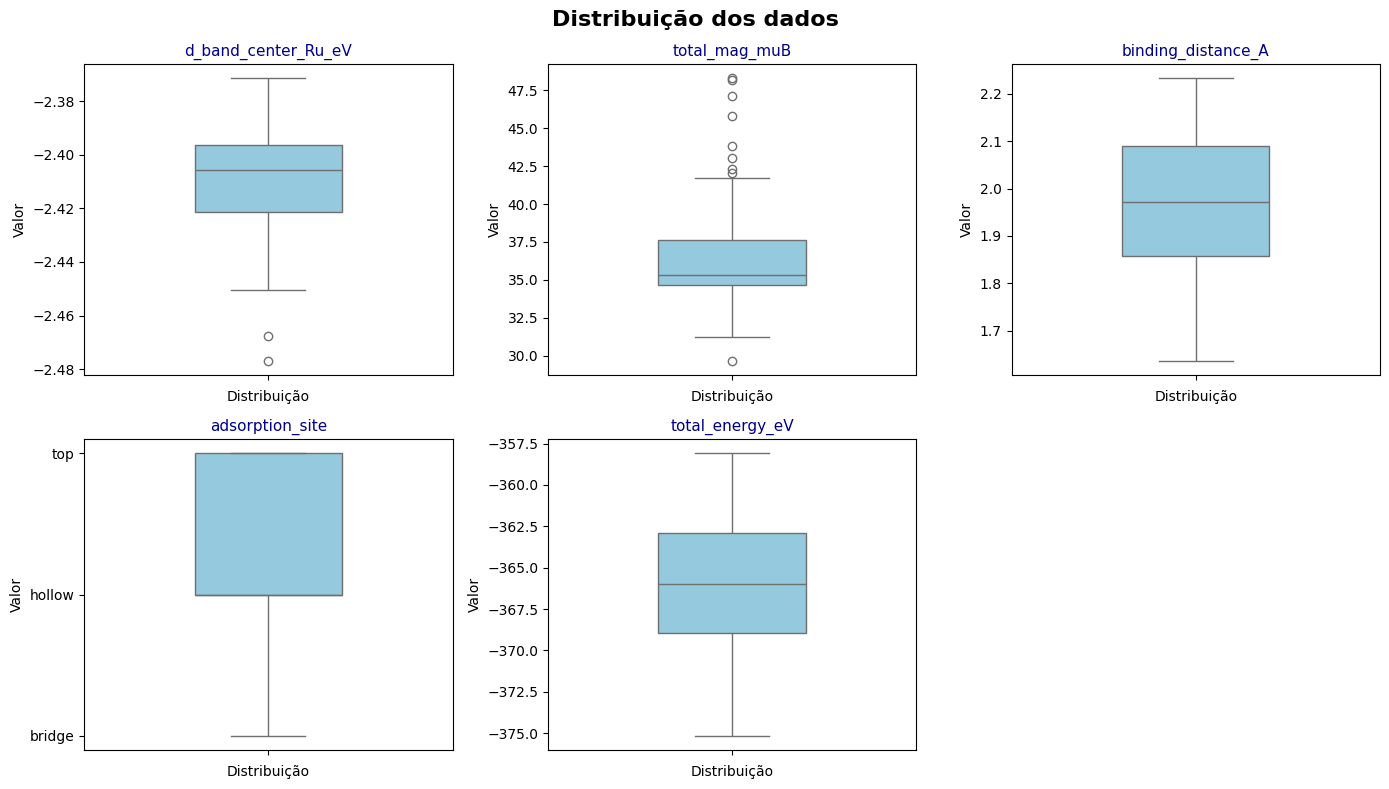

In [85]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 8), sharex=False)
axes = axes.flatten()

for i, col in enumerate(FEATURES+TARGET):
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue", width=0.4)
    axes[i].set_title(col, fontsize=11, color='darkblue')
    axes[i].set_xlabel("Distribuição")
    axes[i].set_ylabel("Valor")
    

# Oculta o útlimo subplot não utilizado
axes[-1].set_visible(False)

fig.suptitle("Distribuição dos dados", fontweight="bold", fontsize=16)
plt.tight_layout()
plt.show()

É possível visualizar como não há uma variação grande na escala dos atributos, ao contrário do alvo. Além disso, existem mais dados sobre o sítio *top* que o resto, o que pode enviesar o modelo.

Realizando a divisão dos dados, separando 10% para teste. Como a proporção entre número de dados e colunas é muito baixo, é necessário escolher poucos atributos para o treinamento. Treinar com todos os dados poderia melhorar a performance do modelo, mas pode causar sobreajuste.

In [86]:
# Split dos índices para separação dos dados
print(f'Tamanho dos dados:{df.shape}')

indices = df.index
indices_train, indices_test = train_test_split(
    indices, test_size=TEST_SIZE, random_state=RANDOM_SEED
)

df_train = df.loc[indices_train]
df_test = df.loc[indices_test]

y_train = df_train[TARGET].to_numpy()
y_test = df_test[TARGET].to_numpy()

Tamanho dos dados:(55, 45)


Realizando um processamento dos dados, aplicando Normalização Padrão para os dados contínuos e conversão simbólico-numérica com o codificador *One-hot* para os dados categóricos. Ajustou-se apenas para as *features*, mantendo o *target*.


In [87]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), continuous_cols),
        ("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), categorical_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Ajuste no treino e transformação em ambos
X_train = preprocessor.fit_transform(df_train[FEATURES])
X_test = preprocessor.transform(df_test[FEATURES])

# Nomes exatos das features após a transformação
feature_names = list(preprocessor.get_feature_names_out())
print(f"Atributos tratados: ({len(feature_names)}):", feature_names)

Atributos tratados: (6): ['d_band_center_Ru_eV', 'total_mag_muB', 'binding_distance_A', 'adsorption_site_bridge', 'adsorption_site_hollow', 'adsorption_site_top']


## Treinamento e Explicação dos Modelos:

Realizou-se o treinamento de 3 modelos: Regressão Linear, Árvore de Decisão e Modelo Ativido Generalizado. As métricas para avaliação de performance incluem o RMSE, $R^2$ e Estatística t, sendo que a Regressão Linear atua modelo *baseline*.

### Regressão Linear:

Realizando a regressão por Mínimos Quadrados Ordinários (OLS), adicionando constante explícita nos dados:

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.266
Model:                            OLS   Adj. R-squared:                  0.181
Method:                 Least Squares   F-statistic:                     3.121
Date:                Fri, 09 Oct 2026   Prob (F-statistic):             0.0172
Time:                        09:20:34   Log-Likelihood:                -131.23
No. Observations:                  49   AIC:                             274.5
Df Residuals:                      43   BIC:                             285.8
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                   -274

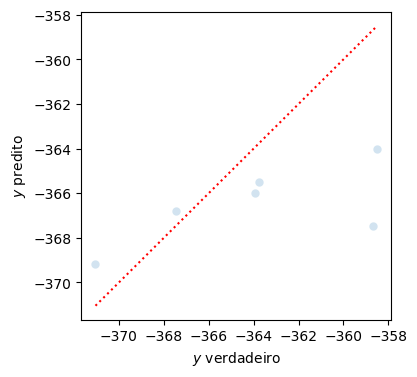

O RMSE do modelo foi de 4.45.


In [88]:
# statsmodels precisa de constante explícita para não gerar R² negativo
X_train_sm = sm.add_constant(pd.DataFrame(X_train, columns=feature_names, index=df_train.index))
X_test_sm = sm.add_constant(pd.DataFrame(X_test, columns=feature_names, index=df_test.index))

modelo_ols = sm.OLS(y_train, X_train_sm).fit()
print(modelo_ols.summary())

# Predição no teste
y_pred_ols = modelo_ols.predict(X_test_sm)
plota_grafico(y_test, y_pred_ols)


Os resultados da regressão indicam que o modelo não é tão eficaz, com um $R^2$ de 0.27, o que é longe do aceitável de >= 0.80. Além disso, a constante teve o maior coeficiente e valor absoluto da estatítica $t$ em módulo. Isso indica que ela é o componente mais importante para a caracterização do modelo, seguido do sítio de adsorção.

Apesar de o modelo ter um baixíssimo RMSE e se ajustar aos dados, conforme o gráfico, essa não se torna uma métrica relevante dado o baixo número de dados de teste. Isso sugere não só que os modelos tendem a sobreajustar os dados quanto não é possível extrair uma estatística extensa.

### Árvore de Decisão:

Para a árvore de decisão treinou-se 2 modelos, um mais simples (com no máximo 6 vértices folha) e um complexo com os valores padrão do modelo:

In [89]:
model_tree_6 = DecisionTreeRegressor(
    max_leaf_nodes=6,
    random_state=RANDOM_SEED,
)

model_tree_6.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,2026
,max_leaf_nodes,6
,min_impurity_decrease,0.0
,ccp_alpha,0.0


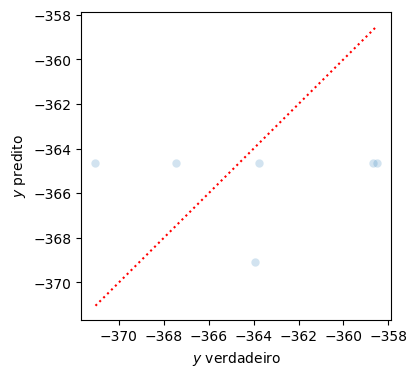

O RMSE do modelo foi de 4.99.


In [90]:
y_pred_6 = model_tree_6.predict(X_test)

plota_grafico(y_test, y_pred_6)

Embora o RMSE do modelo simples tenha sido baixo, pela curva percebe-se que as previsões seguem um comportamento linear, em que o mesmo valor foi predito para diferentes cenários. Analisando pro modelo complexo:

In [91]:
model_tree = DecisionTreeRegressor(
    random_state=RANDOM_SEED,
)

model_tree.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,2026
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


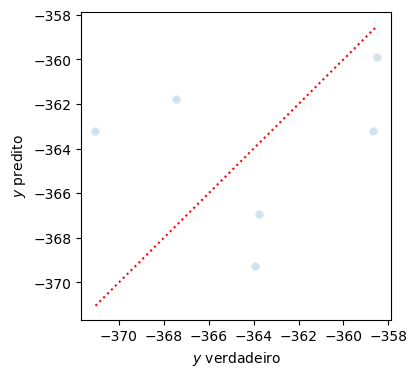

O RMSE do modelo foi de 5.09.


In [92]:
y_pred = model_tree.predict(X_test)

plota_grafico(y_test, y_pred)

A métrica performance do modelo foi similar ao anterior, no entanto a distribuição dos dados está afastado da reta, não tendo um comportamento linear entre o valor real e predito. É possível visualizar os ramos da árvore, a fim de entender quais atributos foram mais relevantes para a separação dos dados:

[Text(0.5, 0.875, 'total_mag_muB <= -0.48\nsamples = 100.0%\nvalue = -366.13'),
 Text(0.3, 0.625, 'd_band_center_Ru_eV <= 0.7\nsamples = 44.9%\nvalue = -368.18'),
 Text(0.4, 0.75, 'True  '),
 Text(0.2, 0.375, 'd_band_center_Ru_eV <= -2.82\nsamples = 36.7%\nvalue = -369.43'),
 Text(0.1, 0.125, 'samples = 2.0%\nvalue = -375.15'),
 Text(0.3, 0.125, 'samples = 34.7%\nvalue = -369.09'),
 Text(0.4, 0.375, 'samples = 8.2%\nvalue = -362.55'),
 Text(0.7, 0.625, 'binding_distance_A <= -1.4\nsamples = 55.1%\nvalue = -364.47'),
 Text(0.6, 0.75, '  False'),
 Text(0.6, 0.375, 'samples = 6.1%\nvalue = -358.77'),
 Text(0.8, 0.375, 'total_mag_muB <= 2.49\nsamples = 49.0%\nvalue = -365.18'),
 Text(0.7, 0.125, 'samples = 44.9%\nvalue = -364.65'),
 Text(0.9, 0.125, 'samples = 4.1%\nvalue = -370.98')]

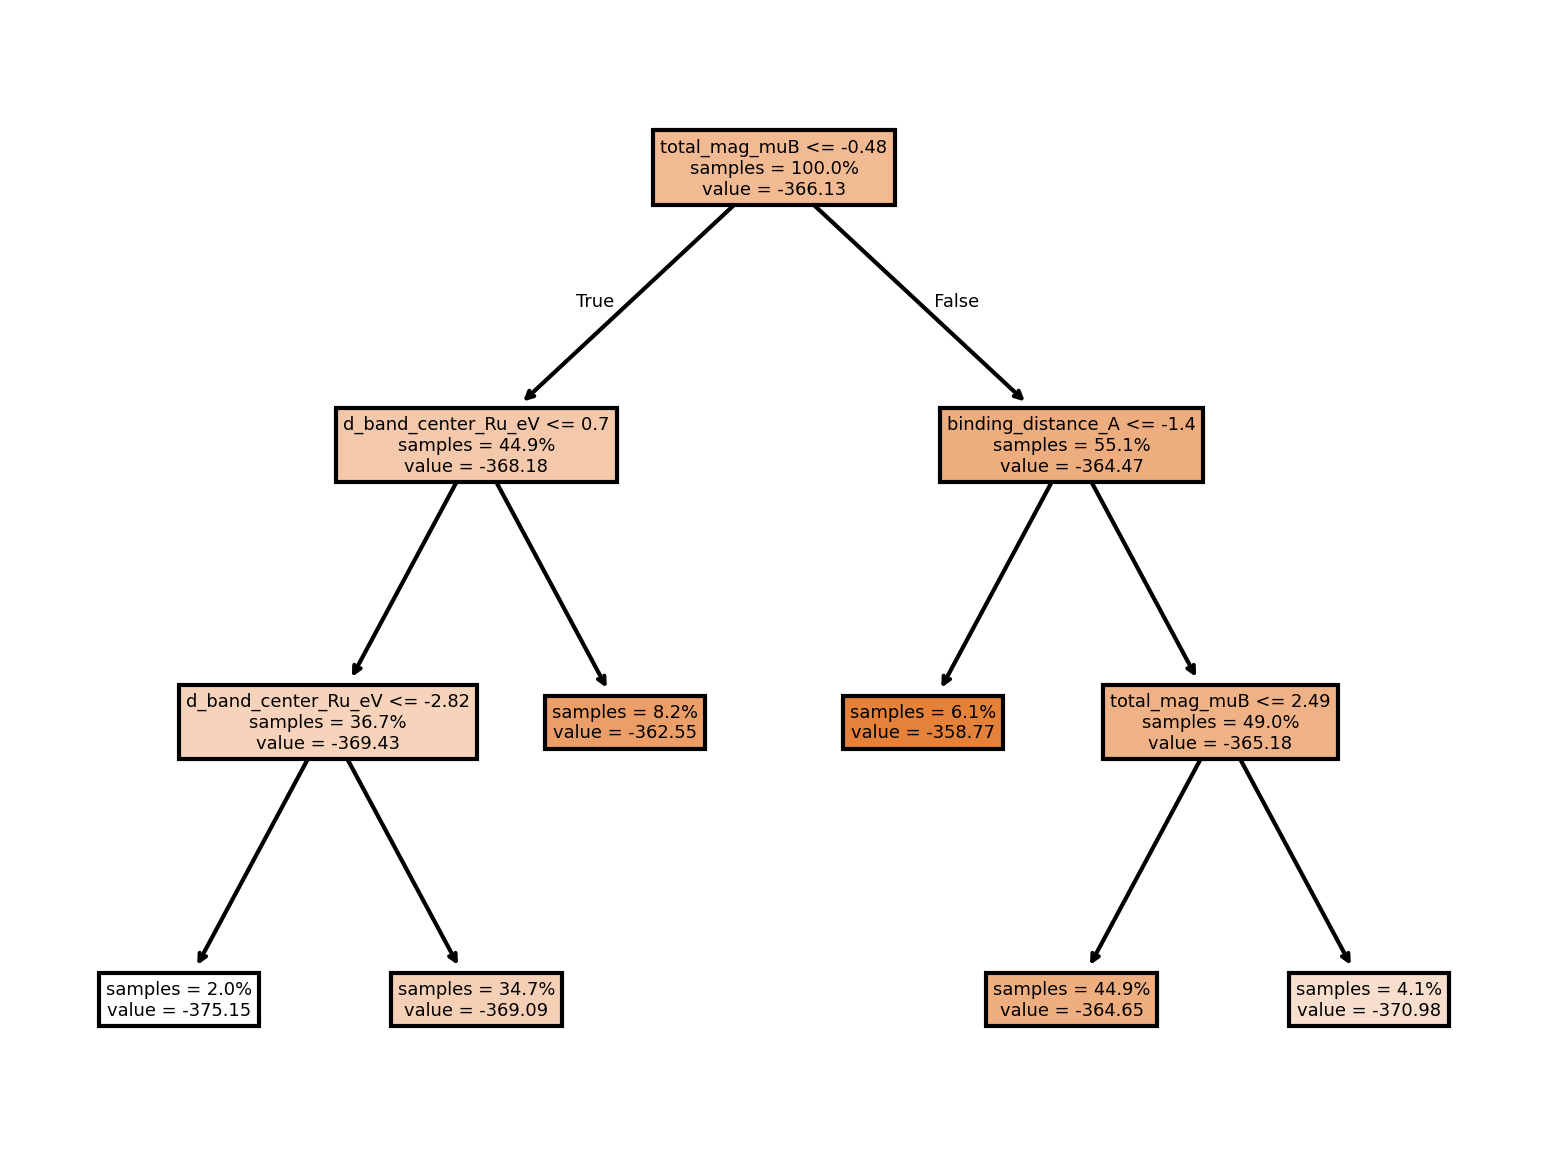

In [93]:
figure, ax = plt.subplots(dpi=300)

plot_tree(
    model_tree_6,
    feature_names=feature_names,
    ax=ax,
    impurity=False,
    filled=True,
    proportion=True,
    precision=2,
)

Nesse caso, a magnetização total foi o atributo mais relevante para o modelo, sendo o primeiro a ramificar os dados e aparecendo também no vértice de decisão. Isso pode indicar que a interação entre o adsorbato e a NP altera a magnetização e estabiliza o sistema, reduzindo a energia total. Por outro lado o fato de não haver o sítio de adsorção como vértice mostra que para este modelo não há uma preferência de sítio que impacta na energia.

[Text(0.5422297297297297, 0.9583333333333334, 'total_mag_muB <= -0.48\nsamples = 100.0%\nvalue = -366.13'),
 Text(0.3614864864864865, 0.875, 'd_band_center_Ru_eV <= 0.7\nsamples = 44.9%\nvalue = -368.18'),
 Text(0.4518581081081081, 0.9166666666666667, 'True  '),
 Text(0.23648648648648649, 0.7916666666666666, 'd_band_center_Ru_eV <= -2.82\nsamples = 36.7%\nvalue = -369.43'),
 Text(0.20945945945945946, 0.7083333333333334, 'samples = 2.0%\nvalue = -375.15'),
 Text(0.2635135135135135, 0.7083333333333334, 'binding_distance_A <= 0.62\nsamples = 34.7%\nvalue = -369.09'),
 Text(0.14864864864864866, 0.625, 'binding_distance_A <= -1.59\nsamples = 26.5%\nvalue = -368.47'),
 Text(0.0945945945945946, 0.5416666666666666, 'total_mag_muB <= -1.09\nsamples = 4.1%\nvalue = -370.62'),
 Text(0.06756756756756757, 0.4583333333333333, 'samples = 2.0%\nvalue = -370.86'),
 Text(0.12162162162162163, 0.4583333333333333, 'samples = 2.0%\nvalue = -370.38'),
 Text(0.20270270270270271, 0.5416666666666666, 'd_band_ce

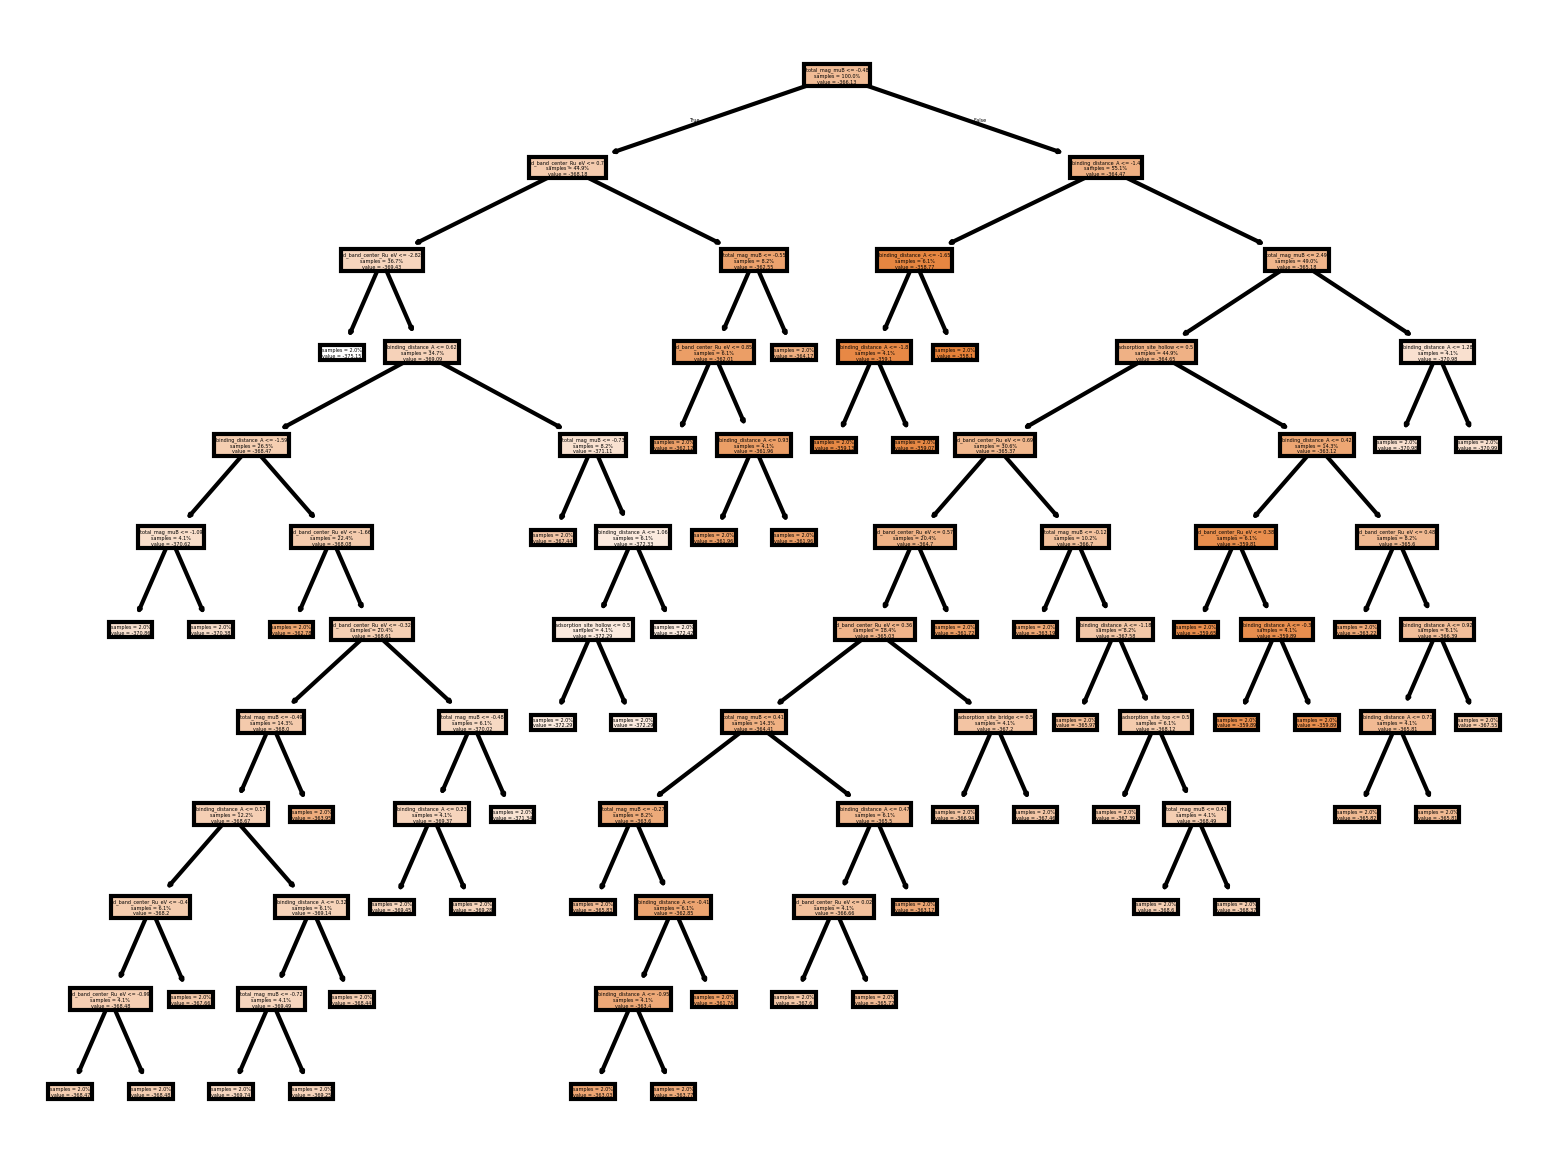

In [94]:
figure, ax = plt.subplots(dpi=300)

plot_tree(
    model_tree,
    feature_names=feature_names,
    ax=ax,
    impurity=False,
    filled=True,
    proportion=True,
    precision=2,
)

Para o modelo complexo é mais difícil de visualizar; porém, pelas informações de texto é possível ter uma noção de como os dados estão sendo distribuídos. Novamente, a magnetização atua como vértice raiz, dividindo em mais de 50% os dados do modelo. Além disso, existem diferentes contribuições dos atributos.

Estimando a importância dos atributos dos modelos simples e complexo, com base na contribuição para a redução da soma dos resíduos quadrados durante o treinamento.


Text(0.5, 1.0, 'Importância dos atributos para modelo simples- Árvore de Decisão')

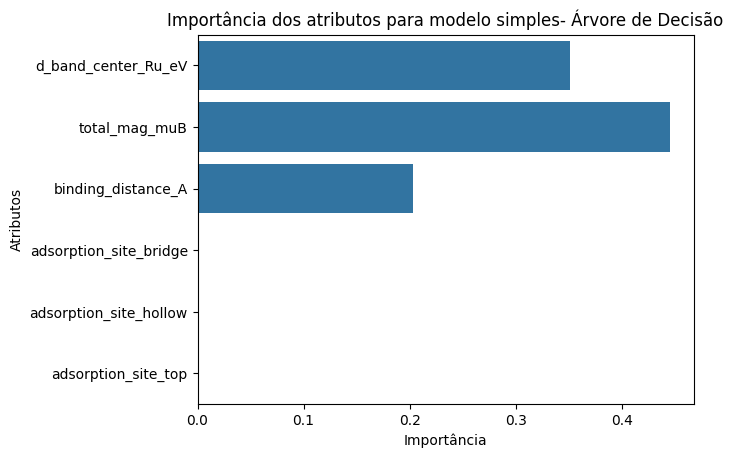

In [95]:
importance_6 = model_tree_6.feature_importances_

ax = sns.barplot(x=importance_6, y=feature_names)
ax.set_xlabel("Importância")
ax.set_ylabel("Atributos")
ax.set_title("Importância dos atributos para modelo simples- Árvore de Decisão")

O gráfico está de acordo com a visualização da árvore, no qual a magnetização atua como o atributo mais importante do modelo, seguido do centro de banda $d$ e a distância de ligação. A ausência do tipo de sítio revela que a classificação binária pode não estar sendo efetiva pro treinamento, ou que existem poucos dados para formar uma estatística decente, ou que de fato esse atributo não interfere na energia do sistema, sendo menos provável.

Text(0.5, 1.0, 'Importância dos atributos para modelo complexo - Árvore de Decisão')

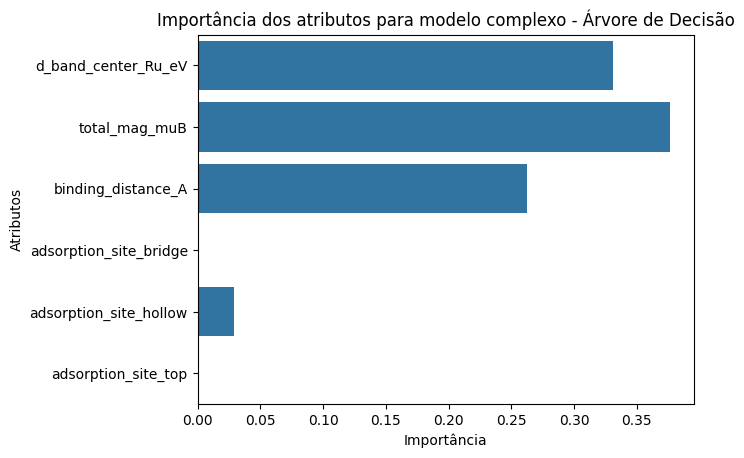

In [96]:
importance = model_tree.feature_importances_

ax = sns.barplot(x=importance, y=feature_names)
ax.set_xlabel("Importância")
ax.set_ylabel("Atributos")
ax.set_title("Importância dos atributos para modelo complexo - Árvore de Decisão")


Embora o modelo complexo siga uma tendência similar, nota-se que existe uma importância (mesmo que baixa) do sitio ser do tipo *hollow*, ou seja, a molécula se ligar entre 3 átomos do catalisador contra 2 e 1 átomos para os sítios *bridge* e *top*, respectivamente.

### Modelos Aditivos Generalizados (GAMs):

Treinando um GAM apenas para os atributos contínuos, com base nos índices obtidos abaixo. O leitor atento pode realizar o mesmo processo variando os atributos considerados, e alterando $s$ por $f$ para variáveis categóricas:

In [97]:
for i, nome in enumerate(FEATURES):
    print(f"{i} \t {nome}")

0 	 d_band_center_Ru_eV
1 	 total_mag_muB
2 	 binding_distance_A
3 	 adsorption_site


In [98]:
terms_GAM = s(0) + s(1) + s(2) + f(3) + f(4) + f(5) # s de b-spline, sendo a função usada para ajustar o modelo com base em cada índice

model_GAM = LinearGAM(terms_GAM).fit(X_train, y_train)
print(model_GAM.summary())

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     16.4585
Link Function:                     IdentityLink Log Likelihood:                                  -141.7128
Number of Samples:                           49 AIC:                                              318.3426
                                                AICc:                                             339.4455
                                                GCV:                                               63.0278
                                                Scale:                                              5.1609
                                                Pseudo R-Squared:                                  -0.0459
Feature Function                  Lam

C:\Users\enzo24035\AppData\Local\Temp\ipykernel_43052\1400695137.py:4: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  print(model_GAM.summary())


Perceba que o modelo não está bom, com um pseudo $R^2$ negativo e uma Validação Cruzada Generalizada (GCV) de 63.03, sendo uma métrica de desempenho para estimar o erro de previsão de um modelo. Treinando com menos atributos:

In [99]:
terms_GAM = s(0) + s(1)  # s de b-spline, sendo a função usada para ajustar o modelo com base em cada índice

model_GAM_simples = LinearGAM(terms_GAM).fit(X_train, y_train)
print(model_GAM_simples.summary())

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     13.9501
Link Function:                     IdentityLink Log Likelihood:                                  -123.8892
Number of Samples:                           49 AIC:                                              277.6787
                                                AICc:                                             292.1087
                                                GCV:                                               24.1765
                                                Scale:                                              3.4965
                                                Pseudo R-Squared:                                   0.4829
Feature Function                  Lam

C:\Users\enzo24035\AppData\Local\Temp\ipykernel_43052\2589829716.py:4: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  print(model_GAM_simples.summary())


A performance melhorou, mas ainda está abaixo do *baseline*; apesar disso, o GCV reduziu 3x, diminuindo o erro na previsão do modelo. Abaixo foi plotado a dependência parcial de cada atributo, analisando como eles afetam o valor do *target* para o modelo completo:

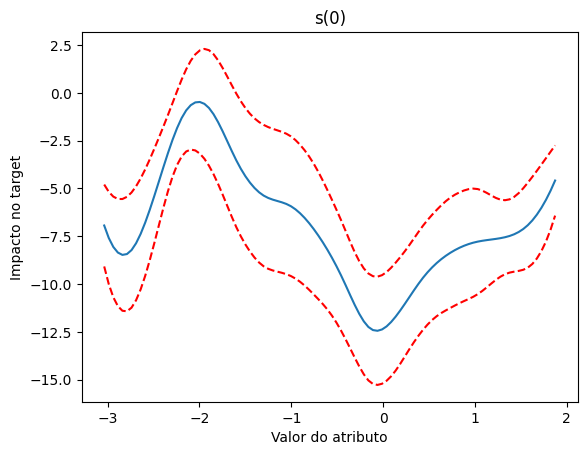

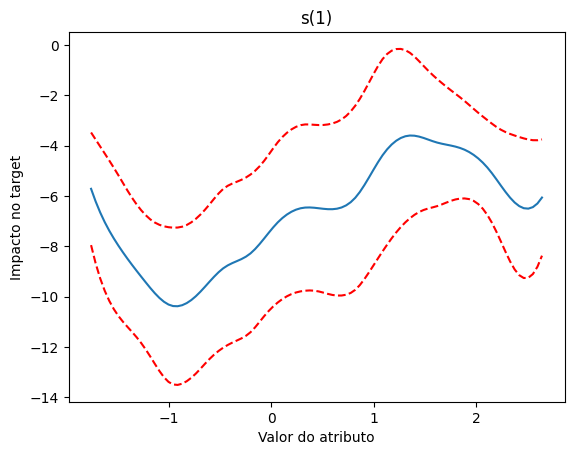

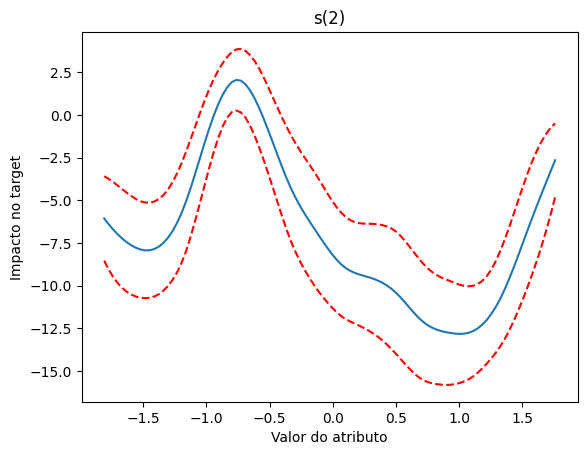

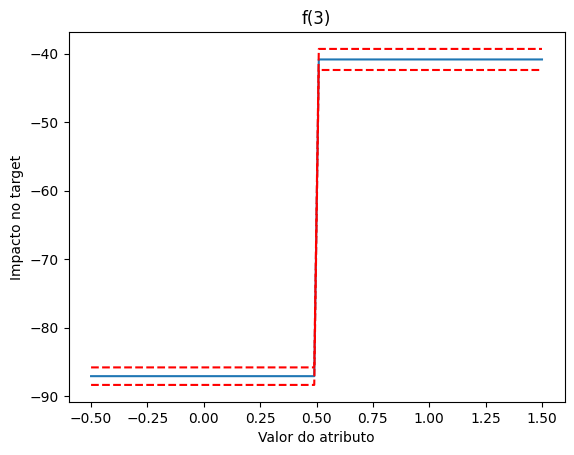

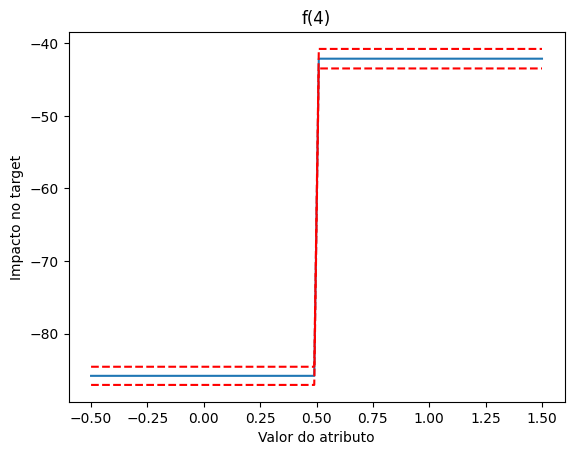

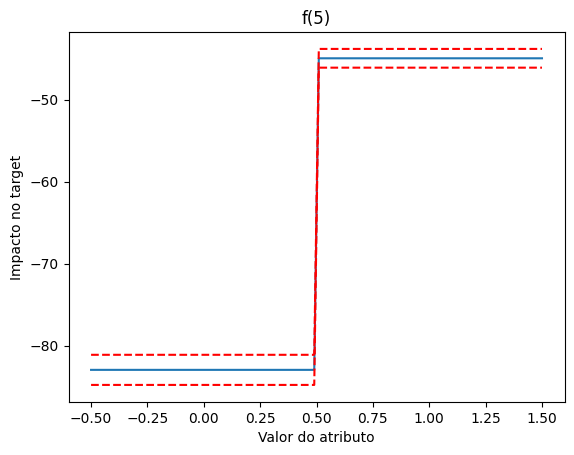

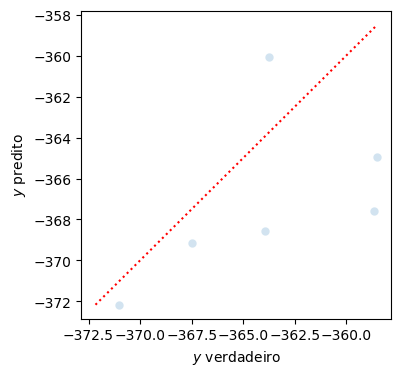

O RMSE do modelo foi de 5.17.


In [103]:
plota_dep_parcial(model_GAM, CONFIANCA)

y_pred_GAM = model_GAM.predict(X_test)

plota_grafico(y_test, y_pred_GAM)

O comportamento do primeiro atributo (centro da banda d do Ru) assemelha-se ao do terceiro (distância de ligação), exibindo um perfil não linear e pico em torno de -2. É importante destacar que a largura do intervalo de confiança reflete o grau de incerteza das estimativas do modelo; a amplitude observada indica uma menor densidade amostral ou maior dispersão nos extremos da distribuição dessas variáveis. Por outro lado, as variáveis categóricas apresentam intervalos mais estreitos, evidenciando estimativas com maior estabilidade estatística.

A magnetização total tem um comportamento mais linear, em que o aumento do atributo impacta positivamente o *target*, reduzindo a energia total. Já o sítio de adsorção provoca o mesmo resultado com a presença do atributo (1) em relação à ausência (0), mas não havendo distinção entre os sítios. Embora isso sugere que não há prevalência de um sítio na estabilização da energia, a escala de impacto é muito maior em relação aos outros atributos, alterando a energia em 40 unidades. 

Por fim, o RMSE se mantem baixo para a escala do *target*, porém os dados não são completamente descritos pela reta em vermelho.

### Dependência Parcial e Expectativa condicional individual (ICE):

Plotando gráficos de Dependência Parcial (PDP) e ICE juntos para a árvore aleatória complexa, visando analisar os exemplos separadamente e como sua média se comporta. Com essas ferramentas de explicação é possível mostrar o efeito que um atributo tem na previsão do modelo, além de analisar relações heterogêneas entre os exemplos.

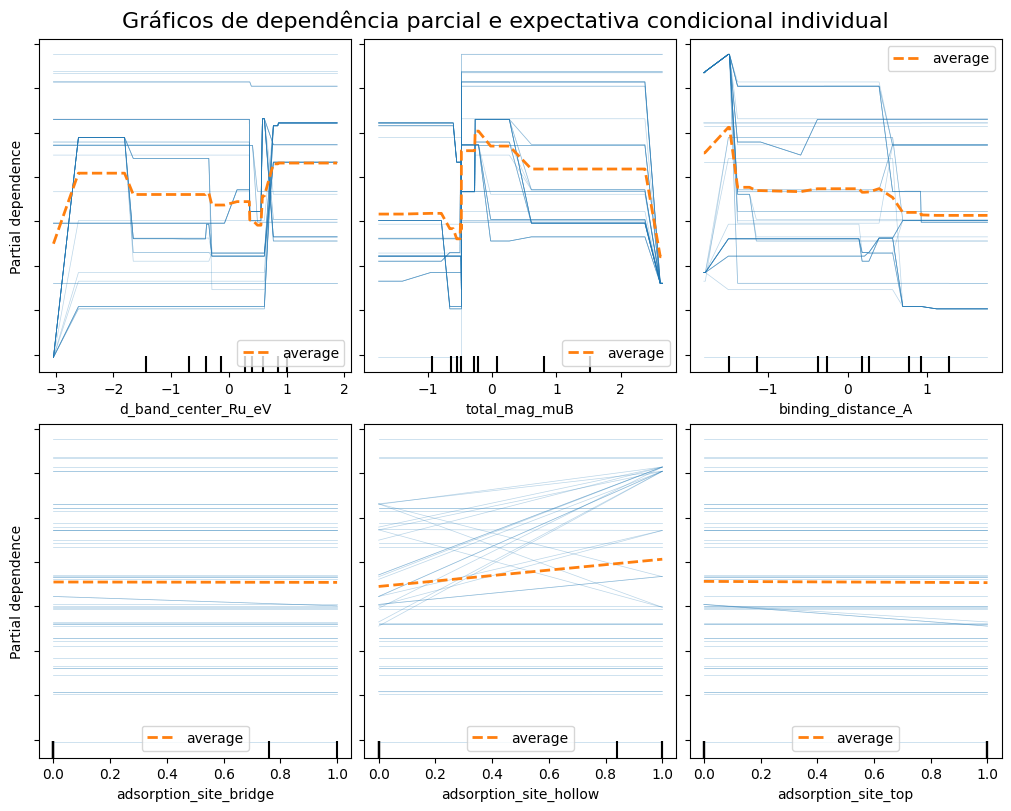

In [111]:
features_para_plotar = [
    "e_fermi_eV", 
    "d_band_center_Ru_eV", 
    "binding_distance_A", 
    "adsorption_site_top"  # Use o nome exato gerado pelo encoder
]

CONFIGURACAO_BASE = {
    "n_jobs": 4,
    "random_state": RANDOM_SEED,
}

INFORMACAO_ATRIBUTOS = {
    "features": feature_names,
    "feature_names": list(feature_names),
    "kind": "both",
}

figura, eixo = plt.subplots(
    ncols=3,
    nrows=2,
    figsize=(10, 8),
    sharey=True,
    constrained_layout=True,
)

PartialDependenceDisplay.from_estimator(
    model_tree,
    X_train,
    ax=eixo,
    pd_line_kw={"color": "tab:orange", "linestyle": "--", "linewidth": 2},
    **INFORMACAO_ATRIBUTOS,
    **CONFIGURACAO_BASE,
)

figura.suptitle("Gráficos de dependência parcial e expectativa condicional individual", fontsize=16);


Para os atributos contínuos, as curvas exibem o formato em degraus característico das regras de divisão de árvores de decisão. O centro da banda d apresenta um patamar elevado nos valores positivos (em torno de $+0.7$), com a maioria das trajetórias individuais seguindo esse salto. A magnetização total atinge um platô de impacto favorável na região central (entre $-0.3$ e $+0.5$), caindo abruptamente nos extremos de baixa e alta magnetização. Em contraste, a distância de ligação mostra um comportamento majoritariamente decrescente, onde afastamentos maiores do adsorbato reduzem o valor estimado pelo modelo.   

Nos atributos binários de sítio, não observa-se uma influência preditiva evidente. Os sítios bridge e top exibem retas médias praticamente horizontais e trajetórias paralelas, indicando relevância quase nula na ramificação dos nós da árvore. Por outro lado, o sítio hollow demonstra uma leve inclinação média ascendente da condição 0 para 1, com perceptível cruzamento nas linhas ICE individuais. Isso evidencia que a sua ativação modula a resposta de forma heterogênea dependendo dos valores dos outros atributos, sendo um sítio mais importante para o modelo.

## Conclusões:

Este estudo destacou como a escolha criteriosa da arquitetura de *Machine Learning* é determinante, já que o trade-off entre flexibilidade e complexidade afeta de forma direta a interpretabilidade dos resultados. Ficou evidente também que expandir o conjunto de dados é fundamental para fortalecer o suporte estatístico e capturar padrões mais consistentes, auxiliando na explicabilidade dos modelos.

O desempenho modesto da regressão linear, cujo ajuste dependeu majoritariamente do termo independente, reforça que correlações lineares simples não descrevem adequadamente a física do sistema. Apesar disso, modelos baseados em árvores conseguiram mapear dependências não lineares mais nítidas, nas quais a magnetização total atuou como o descritor de maior peso nas divisões da árvore. Enquanto a configuração do sítio de adsorção mostrou impacto direto na modulação da energia total para os modelos GAM, o centro de banda d e a distância de ligação tiveram curvas semelhantes, podendo indicar interação entre os atributos. Apesar do tamanho amostral limitado, a abordagem trouxe *insights* valiosos sobre a influência das propriedades eletrônicas e estruturais no comportamento energético das nanopartículas.

## Referências:

[1] K. Skalska, J. S. Miller, S. Ledakowicz, Science of the total environment
408, 3976 (2010).

[2] F. Gholami, M. Tomas, Z. Gholami, M. Vakili, Science of the Total
Environment 714, 136712 (2020).

[3] O. A. Ojelade, S. F. Zaman, B.-J. Ni, Journal of Environmental Mana-
gement 342, 118348 (2023).

[4] L. Zhang, et al., Inorganic Chemistry 61, 8096 (2022).

[5] Z. Zhang, et al., Environmental Science: Nano 7, 2117 (2020).

[6] M. Hong, Q. Wang, J. Sun, C. Wu, Science of The Total Environment
827, 154349 (2022).

[7] D. Qi, et al., Nano Research Energy 1, e9120022 (2022).

[8] XAVIER, Enzo Januzzi. Estudo de nanopartículas de cobre e rutênio para redução de óxido nítrico. 15 f. Projeto de Pesquisa (Iniciação Científica) – Ilum Escola de Ciência, Campinas, 2025.

[9] CASSAR, Daniel Roberto. ATP-203 7.1 - Seleção de atributos. Material de Aula, 2024.

[10] CASSAR, Daniel Roberto. TAV-607 A.3 - Modelos aditivos generalizados (GAM). Material de Aula, 2026.



